In [53]:
import os
import io
import math
import base64
import json
import mimetypes
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive, output
from pathlib import Path
from enum import IntEnum
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter
from IPython.display import (Video, HTML, Javascript, ProgressBar,
                             DisplayHandle, display, update_display, clear_output)

%matplotlib inline

In [2]:
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
dataset_dir = Path("/content/drive/MyDrive/datasets/workoutfitness-video")

print("----- Available exercises -----\n\n- ", end="")
print("\n- ".join(list(map(lambda path: Path(path).name, dataset_dir.iterdir()))))

----- Available exercises -----

- barbell biceps curl
- bench press
- chest fly machine
- deadlift
- decline bench press
- hammer curl
- hip thrust
- incline bench press
- lat pulldown
- lateral raise
- leg extension
- leg raises
- plank
- pull Up
- push-up
- romanian deadlift
- russian twist
- shoulder press
- squat
- t bar row
- tricep Pushdown
- tricep dips


In [4]:
EXERCISE = "deadlift"

In [6]:
# upload exercise estimation files to the directory

N_LANDMARKS = 33
columns = ["video", "frame", "timestamp"] + [
    f"{axis}{i}" for i in range(N_LANDMARKS) for axis in "xyz"
]

df = pd.read_csv(EXERCISE + "-estimations.csv", header=None, names=columns)

In [ ]:
df.head()

,video,frame,timestamp,x0,y0,z0,x1,y1,z1,x2,...,z29,x30,y30,z30,x31,y31,z31,x32,y32,z32
0,deadlift_1.mp4,0,0.0000,-0.032239,-0.183095,-0.725946,-0.017194,-0.223422,-0.719837,-0.016311,...,-0.013437,-0.133350,0.563342,-0.034296,0.112871,0.623815,-0.120198,-0.160220,0.569796,-0.160483
1,deadlift_1.mp4,1,0.0093,-0.032240,-0.183366,-0.725997,-0.017188,-0.223636,-0.719869,-0.016304,...,-0.012488,-0.133075,0.563373,-0.033439,0.112570,0.626080,-0.119316,-0.160146,0.570099,-0.158913
2,deadlift_1.mp4,2,0.0177,-0.032228,-0.183271,-0.726201,-0.017154,-0.223501,-0.720079,-0.016270,...,-0.009922,-0.133037,0.563394,-0.032214,0.112541,0.627485,-0.115955,-0.160252,0.570349,-0.156808
3,deadlift_1.mp4,3,0.0210,-0.031824,-0.183371,-0.726222,-0.016855,-0.223602,-0.720084,-0.015966,...,-0.009709,-0.132898,0.563455,-0.032172,0.112504,0.628250,-0.115840,-0.160251,0.570456,-0.156732
4,deadlift_1.mp4,4,0.0295,-0.031019,-0.183351,-0.726355,-0.016135,-0.223569,-0.720163,-0.015240,...,-0.007933,-0.132792,0.563479,-0.032120,0.112958,0.629106,-0.113618,-0.160268,0.570924,-0.156376


In [7]:

class Point3D:

    def __init__(self, x, y, z):
        self.x = x
        self.y = y
        self.z = z

    def __repr__(self):
        return "(%d,%d,%d)" % (self.x, self.y, self.z)


def get_center(p1, p2):
    return (
        (p1.x + p2.x) / 2,
        (p1.y + p2.y) / 2,
        (p1.z + p2.z) / 2,
    )

# credits: https://stackoverflow.com/a/19730129
def get_angle(p1, p2, p3):
    v1 = Point3D(p1.x - p2.x, p1.y - p2.y, p1.z - p2.z)
    v2 = Point3D(p3.x - p2.x, p3.y - p2.y, p3.z - p2.z)

    v1mag = math.sqrt(v1.x * v1.x + v1.y * v1.y + v1.z * v1.z)
    v1norm = Point3D(v1.x / v1mag, v1.y / v1mag, v1.z / v1mag)

    v2mag = math.sqrt(v2.x * v2.x + v2.y * v2.y + v2.z * v2.z)
    v2norm = Point3D(v2.x / v2mag, v2.y / v2mag, v2.z / v2mag)

    res = v1norm.x * v2norm.x + v1norm.y * v2norm.y + v1norm.z * v2norm.z
    return math.degrees(math.acos(res))

def _odd_window(window, n):
    window = min(window, n)
    if window % 2 == 0:
        window -= 1
    return max(window, 1)


def smooth(values, window=11, poly=3):
    values = np.asarray(values, dtype=float)
    window = _odd_window(window, len(values))
    if window <= poly:
        return values
    return savgol_filter(values, window, poly, axis=0)

def remove_jitters(coordinates, median_kernel=5):
    return median_filter(coordinates, size=median_kernel, mode="nearest")

def get_velocity(y, t, window=31, poly=2):
    n = len(t)
    if n < 2:
        return np.zeros(n)

    window = _odd_window(window, n)
    if window <= poly:
        return np.gradient(y, t)

    dt = np.mean(np.diff(t))
    return savgol_filter(y, window, poly, deriv=1, delta=dt)

class Landmark(IntEnum):
    NOSE = 0
    LEFT_EYE_INNER = 1
    LEFT_EYE = 2
    LEFT_EYE_OUTER = 3
    RIGHT_EYE_INNER = 4
    RIGHT_EYE = 5
    RIGHT_EYE_OUTER = 6
    LEFT_EAR = 7
    RIGHT_EAR = 8
    MOUTH_LEFT = 9
    MOUTH_RIGHT = 10
    LEFT_SHOULDER = 11
    RIGHT_SHOULDER = 12
    LEFT_ELBOW = 13
    RIGHT_ELBOW = 14
    LEFT_WRIST = 15
    RIGHT_WRIST = 16
    LEFT_PINKY = 17
    RIGHT_PINKY = 18
    LEFT_INDEX = 19
    RIGHT_INDEX = 20
    LEFT_THUMB = 21
    RIGHT_THUMB = 22
    LEFT_HIP = 23
    RIGHT_HIP = 24
    LEFT_KNEE = 25
    RIGHT_KNEE = 26
    LEFT_ANKLE = 27
    RIGHT_ANKLE = 28
    LEFT_HEEL = 29
    RIGHT_HEEL = 30
    LEFT_FOOT_INDEX = 31
    RIGHT_FOOT_INDEX = 32

def calculate_body_angle(landmarks, left_landmark_locations: list[Landmark]):

    left_angle = get_angle(
        Point3D(*landmarks[left_landmark_locations[0]]),
        Point3D(*landmarks[left_landmark_locations[1]]),
        Point3D(*landmarks[left_landmark_locations[2]])
    )

    right_angle = get_angle(
        Point3D(*landmarks[left_landmark_locations[0] + 1]),
        Point3D(*landmarks[left_landmark_locations[1] + 1]),
        Point3D(*landmarks[left_landmark_locations[2] + 1])
    )

    return (left_angle + right_angle) / 2

def calculate_hip_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_SHOULDER, Landmark.LEFT_HIP, Landmark.LEFT_KNEE ])

def calculate_knee_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_HIP, Landmark.LEFT_KNEE, Landmark.LEFT_HEEL ])

def calculate_ankle_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_KNEE, Landmark.LEFT_HEEL, Landmark.LEFT_FOOT_INDEX ])

def calculate_shoulder_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_HIP, Landmark.LEFT_SHOULDER, Landmark.LEFT_ELBOW  ])

def calculate_elbow_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_SHOULDER, Landmark.LEFT_ELBOW, Landmark.LEFT_WRIST ])

def calculate_wrist_angle(estimations):
    return calculate_body_angle(estimations, [ Landmark.LEFT_ELBOW, Landmark.LEFT_WRIST, Landmark.LEFT_INDEX ])

def get_3d_center(landmarks):
    left_index_finger, right_index_finger = landmarks[19], landmarks[20]
    return get_center(Point3D(*left_index_finger), Point3D(*right_index_finger))



In [24]:
def get_metrics(estimations):
  landmarks = estimations["landmarks"]
  timestamps = estimations["timestamps"]

  history = {
    "displacement": [],
    "timestamps": [],
    "angular_distances": {
      "hip": [], "knee": [], "ankle": [], "wrist": [], "elbow": [], "shoulder": []
    }
  }
  for i, (landmark, timestamp) in enumerate(zip(landmarks, timestamps)):
    center = get_3d_center(landmark)
    history["displacement"].append(center)
    history["timestamps"].append(timestamp)
    history["angular_distances"]["hip"].append(calculate_hip_angle(landmark))
    history["angular_distances"]["knee"].append(calculate_knee_angle(landmark))
    history["angular_distances"]["ankle"].append(calculate_ankle_angle(landmark))
    history["angular_distances"]["wrist"].append(calculate_wrist_angle(landmark))
    history["angular_distances"]["elbow"].append(calculate_elbow_angle(landmark))
    history["angular_distances"]["shoulder"].append(calculate_shoulder_angle(landmark))
  ts = np.asarray(history["timestamps"], dtype=float)
  t = (ts - ts[0]) / 1_000_000_000.0
  pos = np.asarray(history["displacement"])

  processed_history = {
    "time": t,
    "displacement": remove_jitters(smooth(pos[:, 1] - pos[0, 1])),
    "angular_distances": {
        "hip": remove_jitters(smooth(history["angular_distances"]["hip"])),
        "knee": remove_jitters(smooth(history["angular_distances"]["knee"])),
        "ankle": remove_jitters(smooth(history["angular_distances"]["ankle"])),
        "wrist": remove_jitters(smooth(history["angular_distances"]["wrist"])),
        "elbow": remove_jitters(smooth(history["angular_distances"]["elbow"])),
        "shoulder": remove_jitters(smooth(history["angular_distances"]["shoulder"])),
    }
  }

  processed_history["velocity"] = get_velocity(processed_history["displacement"], t)
  processed_history["angular_velocities"] = {
      "hip": get_velocity(processed_history["angular_distances"]["hip"], t),
      "knee": get_velocity(processed_history["angular_distances"]["knee"], t),
      "ankle": get_velocity(processed_history["angular_distances"]["ankle"], t),
      "wrist": get_velocity(processed_history["angular_distances"]["wrist"], t),
      "elbow": get_velocity(processed_history["angular_distances"]["elbow"], t),
      "shoulder": get_velocity(processed_history["angular_distances"]["shoulder"], t),
  }

  return processed_history

In [25]:
exercise_path = dataset_dir / EXERCISE

landmarks_by_video = {
    name: {
        "landmarks": g.sort_values("frame")[columns[3:]].to_numpy().reshape(-1, N_LANDMARKS, 3),
        "timestamps": g.sort_values("timestamp")[columns[2]].to_numpy()
    }
    for name, g in df.groupby("video")
}



In [51]:
def plot_metrics(metrics):
  fig, axes = plt.subplots(2, 2, sharex=True, figsize=(10, 10))

  for ax in axes.flatten():
    ax.cla()

  t = metrics["time"]

  axes[0, 0].plot(t, -metrics["displacement"])
  axes[0, 0].set_ylabel("Displacement (m)")
  axes[0, 0].set_xlabel("Time (s)")

  axes[0, 1].plot(t, -metrics["velocity"])
  axes[0, 1].set_ylabel("Velocity (m/s)")
  axes[0, 1].set_xlabel("Time (s)")

  axes[1, 0].plot(t, metrics["angular_distances"]["hip"], label="Hip")
  axes[1, 0].plot(t, metrics["angular_distances"]["knee"], label="Knee")
  axes[1, 0].plot(t, metrics["angular_distances"]["elbow"], label="Elbow")
  axes[1, 0].plot(t, metrics["angular_distances"]["shoulder"], label="Shoulder")
  axes[1, 0].set_ylabel("Angular distance (deg)")
  axes[1, 0].set_xlabel("Time (s)")
  axes[1, 0].legend()

  axes[1, 1].plot(t, metrics["angular_velocities"]["hip"], label="Hip")
  axes[1, 1].plot(t, metrics["angular_velocities"]["knee"], label="Knee")
  axes[1, 1].plot(t, metrics["angular_velocities"]["elbow"], label="Elbow")
  axes[1, 1].plot(t, metrics["angular_velocities"]["shoulder"], label="Shoulder")
  axes[1, 1].set_ylabel("Angular velocities (deg/s)")
  axes[1, 1].set_xlabel("Time (s)")
  axes[1, 1].legend()

  plt.show()

In [46]:
PHASE_MAP = {
    "squat":                ("knee",     "increasing"),
    "leg extension":        ("knee",     "increasing"),
    "deadlift":             ("hip",      "increasing"),
    "romanian deadlift":    ("hip",      "increasing"),
    "hip thrust":           ("hip",      "increasing"),
    "leg raises":           ("hip",      "decreasing"),
    "push up":              ("elbow",    "increasing"),
    "bench press":          ("elbow",    "increasing"),
    "incline bench press":  ("elbow",    "increasing"),
    "decline bench press":  ("elbow",    "increasing"),
    "shoulder press":       ("elbow",    "increasing"),
    "tricep dips":          ("elbow",    "increasing"),
    "tricep pushdown":      ("elbow",    "increasing"),
    "barbell biceps curl":  ("elbow",    "decreasing"),
    "hammer curl":          ("elbow",    "decreasing"),
    "lat pulldown":         ("elbow",    "decreasing"),
    "pull up":              ("elbow",    "decreasing"),
    "t bar row":            ("elbow",    "decreasing"),
    "lateral raise":        ("shoulder", "increasing"),
}

OTHER, ECCENTRIC, CONCENTRIC, STATIC = 0, 1, 2, 3
PHASE_NAMES = ["other", "eccentric", "concentric", "static"]

STILL_FRAC = 0.15     # |velocity| below this fraction of the peak counts as "not moving"
LOCKOUT_ZONE = 0.15   # "at the lockout end" = within this fraction of the video's range of motion
MIN_LEN = 3           # runs shorter than this many frames get absorbed into the previous phase


def classify_phase(pos, vel, concentric):
    pos, vel = np.asarray(pos, dtype=float), np.asarray(vel, dtype=float)
    thr = STILL_FRAC * np.nanmax(np.abs(vel))
    rising, falling = vel > thr, vel < -thr
    still = ~(rising | falling)

    codes = np.full(len(vel), OTHER)
    if concentric == "increasing":
        codes[rising], codes[falling] = CONCENTRIC, ECCENTRIC
    else:
        codes[falling], codes[rising] = CONCENTRIC, ECCENTRIC

    # lockout = still AND sitting at the end of the concentric direction
    # (top of the angle range if the concentric part increases it, bottom if it decreases it)
    norm = (pos - np.nanmin(pos)) / (np.nanmax(pos) - np.nanmin(pos) + 1e-9)
    at_lockout = norm > 1 - LOCKOUT_ZONE if concentric == "increasing" else norm < LOCKOUT_ZONE
    codes[still & at_lockout] = STATIC     # still but NOT at lockout (bottom pause, setup) stays "other"

    # absorb very short runs into the previous phase
    start = 0
    for i in range(1, len(codes) + 1):
        if i == len(codes) or codes[i] != codes[start]:
            if i - start < MIN_LEN and start > 0:
                codes[start:i] = codes[start - 1]
            start = i
    return codes


metrics_by_video = {name: get_metrics(est) for name, est in landmarks_by_video.items()}

# exercises not in PHASE_MAP fall back to vertical hand displacement (y points down, so up = decreasing)
joint, concentric = PHASE_MAP.get(
    EXERCISE.lower().replace("-", " ").replace("_", " "), (None, "decreasing")
)

phases_by_video = {}
for name, m in metrics_by_video.items():
    pos = m["angular_distances"][joint] if joint else m["displacement"]
    vel = m["angular_velocities"][joint] if joint else m["velocity"]
    phases_by_video[name] = [PHASE_NAMES[c] for c in classify_phase(pos, vel, concentric)]

/tmp/ipykernel_684/3633324455.py:25: RuntimeWarning: invalid value encountered in scalar divide
  v1norm = Point3D(v1.x / v1mag, v1.y / v1mag, v1.z / v1mag)
/tmp/ipykernel_684/3633324455.py:28: RuntimeWarning: invalid value encountered in scalar divide
  v2norm = Point3D(v2.x / v2mag, v2.y / v2mag, v2.z / v2mag)



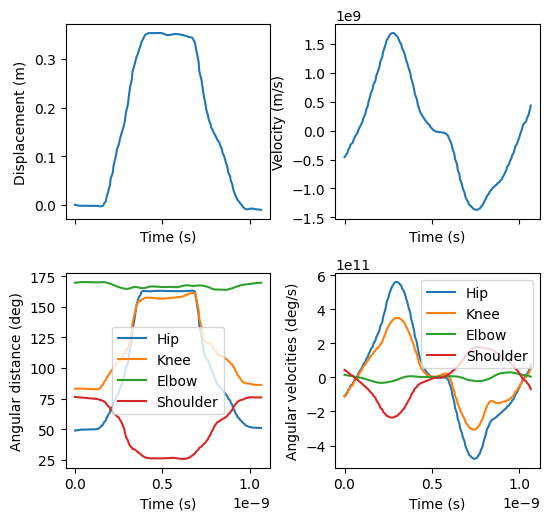

<IPython.core.display.Javascript object>

In [54]:
FLIP_Y = False
VIDEO_W = 460
IMG_W = 560


def metrics_png(metrics):
    real_show, plt.show = plt.show, lambda *a, **k: None
    try:
        plot_metrics(metrics)
    finally:
        plt.show = real_show
    fig = plt.gcf()
    fig.set_size_inches(IMG_W / 100, IMG_W / 100 * 0.95)
    fig.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode()

video_paths = sorted(exercise_path.iterdir())
items = []
pb = ProgressBar(len(video_paths))
pb.display()
for n, p in enumerate(video_paths):
    cap = cv2.VideoCapture(str(p))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    cap.release()
    est = landmarks_by_video.get(p.name)
    m = metrics_by_video.get(p.name)
    items.append({
        "path": p, "name": p.name, "fps": fps,
        "pose": est["landmarks"].round(4).tolist() if est else [],
        "phase": phases_by_video.get(p.name, []),
        "graphs": metrics_png(m) if m is not None else None,
    })
    pb.progress = n + 1
clear_output(wait=True)

LAYOUT = """
<div id="vp" tabindex="0" style="font-family:sans-serif;display:flex;gap:10px;flex-wrap:wrap;align-items:flex-start;outline:none">
  <div style="width:__VW__px">
    <div style="display:flex;align-items:baseline;gap:12px;margin-bottom:4px">
      <b>__NAME__</b><span style="color:#888">__COUNT__</span>
      <span id="vp-phase" style="margin-left:auto;font-size:18px;font-weight:bold;color:#888">other</span>
    </div>
    __VIDEO__
    <div style="margin:6px 0;display:flex;gap:6px;align-items:center;flex-wrap:wrap">
      <button id="vp-prev">&#9664; Prev</button>
      <button id="vp-play">Play/Pause</button>
      <button id="vp-next">Next &#9654;</button>
      <label>Speed
        <select id="vp-speed">
          <option>0.25</option><option>0.5</option><option selected>1</option><option>1.5</option><option>2</option>
        </select>
      </label>
    </div>
    <div style="display:flex;gap:8px">
      <canvas id="vp-front" width="226" height="230" style="background:#111;border-radius:8px"></canvas>
      <canvas id="vp-side"  width="226" height="230" style="background:#111;border-radius:8px"></canvas>
    </div>
  </div>
  <div style="width:__IW__px;max-width:100%">__GRAPHS__</div>
</div>
"""

JS = """
(() => {
  const D = __DATA__;
  const v = document.getElementById('vp-video');
  const front = document.getElementById('vp-front').getContext('2d');
  const side  = document.getElementById('vp-side').getContext('2d');
  const phaseEl = document.getElementById('vp-phase');
  const speedEl = document.getElementById('vp-speed');
  const CONNECTIONS = [[0,1],[1,2],[2,3],[3,7],[0,4],[4,5],[5,6],[6,8],[9,10],
    [11,12],[11,13],[13,15],[15,17],[15,19],[15,21],[17,19],[12,14],[14,16],[16,18],
    [16,20],[16,22],[18,20],[11,23],[12,24],[23,24],[23,25],[24,26],[25,27],[26,28],
    [27,29],[28,30],[29,31],[30,32],[27,31],[28,32]];
  const SCALE = 120;
  const COLORS = {eccentric: '#e53935', concentric: '#43a047', static: '#fb8c00', other: '#888'};

  cancelAnimationFrame(window.__vpRaf);   // stop the loop of the previous video

  const goto = (n, autoplay) =>
    google.colab.kernel.invokeFunction('vp.goto', [n, !!autoplay], {});

  // ---- Actions: keyboard (or anything else) should call these ----
  const actions = {
    togglePlay: () => v.paused ? v.play() : v.pause(),
    next:       () => goto(D.i + 1),
    prev:       () => goto(D.i - 1),
    seek:       (s) => { v.currentTime = Math.max(0, v.currentTime + s); },
    speed:      (r) => { v.playbackRate = r; speedEl.value = r; },
  };
  document.getElementById('vp-prev').onclick = actions.prev;
  document.getElementById('vp-next').onclick = actions.next;
  document.getElementById('vp-play').onclick = actions.togglePlay;
  speedEl.onchange = e => actions.speed(parseFloat(e.target.value));
  v.onended = () => goto(D.i + 1, true);
  v.playbackRate = parseFloat(speedEl.value);

  // ---- Keyboard controls: OFF for now. Flip to true (and edit KEYMAP) later. ----
  const ENABLE_KEYBOARD = false;
  const KEYMAP = {
    ' ':          () => actions.togglePlay(),
    'ArrowRight': () => actions.seek(5),
    'ArrowLeft':  () => actions.seek(-5),
    'n':          () => actions.next(),
    'p':          () => actions.prev(),
  };
  const root = document.getElementById('vp');
  root.onkeydown = null;
  if (ENABLE_KEYBOARD) {
    root.onkeydown = e => { const fn = KEYMAP[e.key]; if (fn) { e.preventDefault(); fn(); } };
  }

  function draw(ctx, pts, label) {
    const w = ctx.canvas.width, h = ctx.canvas.height;
    ctx.clearRect(0, 0, w, h);
    ctx.fillStyle = '#888'; ctx.font = '12px sans-serif'; ctx.fillText(label, 8, 16);
    if (!pts) return;
    const P = pts.map(([a, b]) => [w / 2 + a * SCALE, h / 2 + (D.flipY ? -b : b) * SCALE]);
    ctx.strokeStyle = '#4fc3f7'; ctx.lineWidth = 3;
    for (const [a, b] of CONNECTIONS) {
      ctx.beginPath(); ctx.moveTo(P[a][0], P[a][1]); ctx.lineTo(P[b][0], P[b][1]); ctx.stroke();
    }
    ctx.fillStyle = '#ffca28';
    for (const [x, y] of P) { ctx.beginPath(); ctx.arc(x, y, 3.5, 0, 6.2832); ctx.fill(); }
  }

  function render() {
    if (D.pose.length) {
      const f = Math.min(D.pose.length - 1, Math.max(0, Math.round(v.currentTime * D.fps)));
      const lm = D.pose[f];
      const empty = lm.every(p => p[0] === 0 && p[1] === 0 && p[2] === 0);
      draw(front, empty ? null : lm.map(p => [p[0], p[1]]), 'front (x, y)');
      draw(side,  empty ? null : lm.map(p => [p[2], p[1]]), 'side (z, y)');
      const ph = D.phase[f] || 'other';
      phaseEl.textContent = ph;
      phaseEl.style.color = COLORS[ph];
    } else {
      draw(front, null, 'no estimations'); draw(side, null, '');
      phaseEl.textContent = '-';
    }
    window.__vpRaf = requestAnimationFrame(render);
  }
  render();
})();
"""

html_h = DisplayHandle("vp-html")
state = {"shown": False}

def show(i, autoplay=False):
    i = int(i) % len(items)
    it = items[i]
    video = Video(
        str(it["path"]), embed=True, width=VIDEO_W,
        html_attributes='controls autoplay id="vp-video"' if autoplay else 'controls id="vp-video"',
    )
    graphs = (f'<img style="width:100%" src="data:image/png;base64,{it["graphs"]}">'
              if it["graphs"] else "<i>no metrics for this video</i>")
    layout = (LAYOUT
              .replace("__VW__", str(VIDEO_W))
              .replace("__IW__", str(IMG_W))
              .replace("__NAME__", it["name"])
              .replace("__COUNT__", f"{i + 1} / {len(items)}")
              .replace("__VIDEO__", video._repr_html_())
              .replace("__GRAPHS__", graphs))
    js = Javascript(JS.replace("__DATA__", json.dumps({
        "i": i, "fps": it["fps"], "pose": it["pose"], "phase": it["phase"], "flipY": FLIP_Y,
    })))

    if state["shown"]:
        html_h.update(HTML(layout))
        update_display(js, display_id="vp-js")
    else:
        html_h.display(HTML(layout))
        display(js, display_id="vp-js")
        state["shown"] = True

output.register_callback("vp.goto", show)
show(0)